# ResNet18 — Image Resolution Experiment

## 1. Experiment Configuration

### Objective
Investigate whether increasing input resolution improves
driver-independent classification performance.

### Comparison
- Baseline resolution: 256×192
- Experimental resolution: 384×288

### Controlled Variables
- Architecture: ImageNet-pretrained ResNet18
- Training images: 15,732
- Validation images: 3,603
- Optimizer: AdamW
- Backbone learning rate: 0.0001
- Classifier learning rate: 0.001
- Weight decay: 0.0001
- Batch size: 32
- Maximum epochs: 15
- Checkpoint selection: Validation Macro-F1
- Random seed: 42

Only input resolution changes.

The final held-out test dataset remains untouched.

In [1]:
import torch
import torch.nn as nn
import torchvision
import pandas as pd
import numpy as np
import random
import time
import json

from pathlib import Path
from PIL import Image

from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import f1_score

# ==========================================
# 1. Configuration
# ==========================================

ROOT = Path("..")

SEED = 42

IMAGE_WIDTH = 384
IMAGE_HEIGHT = 288

BATCH_SIZE = 32

MAX_EPOCHS = 15
MIN_EPOCHS = 7
PATIENCE = 5

BACKBONE_LR = 0.0001
CLASSIFIER_LR = 0.001
WEIGHT_DECAY = 0.0001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ==========================================
# 2. Load Existing Driver-Based Splits
# ==========================================

train_df = pd.read_csv(
    ROOT / "data/splits/driver_based/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
)

image_root = ROOT / "data/raw/imgs/train"

assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)

assert len(train_df) == 15732
assert len(val_df) == 3603


# ==========================================
# 3. ImageNet Normalization
# ==========================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ==========================================
# 4. Training Transformations
# ==========================================

train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_HEIGHT, IMAGE_WIDTH)
    ),

    transforms.RandomAffine(
        degrees=5,
        translate=(0.04, 0.04),
        scale=(0.97, 1.03),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ==========================================
# 5. Validation Transformations
# ==========================================

val_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_HEIGHT, IMAGE_WIDTH)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ==========================================
# 6. Dataset Class
# ==========================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        image_path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        label = int(row["classname"][1:])

        return image, label


# ==========================================
# 7. Create DataLoaders
# ==========================================

train_dataset = DriverDataset(
    train_df,
    train_transform
)

val_dataset = DriverDataset(
    val_df,
    val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ==========================================
# 8. Verify
# ==========================================

images, labels = next(iter(train_loader))

print("\nTraining images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\nTraining drivers:", train_df["subject"].nunique())
print("Validation drivers:", val_df["subject"].nunique())

print("\nImage batch:", images.shape)
print("Labels:", labels.shape)

print("\nResolution experiment data ready!")

Device: cuda

Training images: 15732
Validation images: 3603

Training drivers: 18
Validation drivers: 4

Image batch: torch.Size([32, 3, 288, 384])
Labels: torch.Size([32])

Resolution experiment data ready!


## 2. Initialize ResNet18

Load a fresh ImageNet-pretrained ResNet18.

Replace the original classifier with 10 output classes.

Fine-tune all layers using the same configuration as
the 256×192 baseline.

In [2]:
# ==========================================
# 1. Load Original ImageNet Weights
# ==========================================

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace classifier
model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)


# ==========================================
# 2. Configure Optimizer
# ==========================================

backbone_params = [
    p for name, p in model.named_parameters()
    if not name.startswith("fc.")
]

classifier_params = list(model.fc.parameters())

optimizer = torch.optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss()


# ==========================================
# 3. Verify Model
# ==========================================

print("Model: ResNet18")
print("Initialization: ImageNet pretrained")

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

model.eval()

with torch.no_grad():

    sample_output = model(
        images[:2].to(device)
    )

print("Input:", images[:2].shape)
print("Output:", sample_output.shape)

assert sample_output.shape == (2, 10)

print("\nResNet18 ready for full fine-tuning!")

Model: ResNet18
Initialization: ImageNet pretrained
Trainable parameters: 11181642
Input: torch.Size([2, 3, 288, 384])
Output: torch.Size([2, 10])

ResNet18 ready for full fine-tuning!


In [3]:
# ==========================================
# 1. Experiment Directories
# ==========================================

exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "resnet18/resolution_384x288"
)

model_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/resolution_384x288"
)

exp_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

best_model_path = model_dir / "best_model.pt"

history_path = exp_dir / "training_history.csv"
results_path = exp_dir / "results.json"
config_path = exp_dir / "configuration.json"


# ==========================================
# 2. Save Configuration
# ==========================================

config = {
    "model": "ResNet18",
    "pretrained": "ImageNet",
    "fine_tuning": "all_layers",

    "image_width": IMAGE_WIDTH,
    "image_height": IMAGE_HEIGHT,

    "training_images": len(train_dataset),
    "validation_images": len(val_dataset),

    "batch_size": BATCH_SIZE,
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,
    "optimizer": "AdamW",

    "max_epochs": MAX_EPOCHS,
    "min_epochs": MIN_EPOCHS,
    "patience": PATIENCE,

    "augmentation": {
        "rotation": 5,
        "translation": 0.04,
        "scale": [0.97, 1.03],
        "brightness": 0.15,
        "contrast": 0.15
    },

    "checkpoint_selection": "validation_macro_f1",
    "seed": SEED
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)


# ==========================================
# 3. Initialize Training Variables
# ==========================================

history = []

best_f1 = -1.0
best_epoch = 0
best_accuracy = 0.0

no_improvement = 0

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

start_total = time.perf_counter()


# ==========================================
# 4. Training Loop
# ==========================================

for epoch in range(1, MAX_EPOCHS + 1):

    # --------------------------------------
    # Training
    # --------------------------------------

    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    start_train = time.perf_counter()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    train_time = time.perf_counter() - start_train

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total


    # --------------------------------------
    # Validation
    # --------------------------------------

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_true = []
    all_pred = []

    start_val = time.perf_counter()

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

            all_true.extend(
                labels.cpu().tolist()
            )

            all_pred.extend(
                predictions.cpu().tolist()
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    val_time = time.perf_counter() - start_val


    # --------------------------------------
    # Calculate Metrics
    # --------------------------------------

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    # --------------------------------------
    # Save Epoch Results
    # --------------------------------------

    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),
        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),
        "train_time_seconds": float(train_time),
        "val_time_seconds": float(val_time),
        "epoch_time_seconds": float(train_time + val_time)
    })

    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )


    # --------------------------------------
    # Save Best Checkpoint
    # --------------------------------------

    improved = val_macro_f1 > best_f1 + 1e-4

    if improved:

        best_f1 = float(val_macro_f1)
        best_accuracy = float(val_accuracy)
        best_epoch = epoch

        torch.save(
            model.state_dict(),
            best_model_path
        )


    # --------------------------------------
    # Print Progress
    # --------------------------------------

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f} | "
        f"Time: {train_time + val_time:.1f}s",
        flush=True
    )


    # --------------------------------------
    # Early Stopping
    # --------------------------------------

    if epoch <= MIN_EPOCHS:

        no_improvement = 0

    else:

        if improved:
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= PATIENCE:

            print(f"\nEarly stopping at epoch {epoch}")
            break


# ==========================================
# 5. Total Time
# ==========================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - start_total

peak_gpu_memory = (
    torch.cuda.max_memory_allocated() / 1024**2
    if device.type == "cuda"
    else None
)


# ==========================================
# 6. Save Final Results
# ==========================================

history_df = pd.DataFrame(history)

best_record = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]

results = {
    "model": "ResNet18",
    "resolution": "384x288",

    "epochs_completed": len(history),
    "best_epoch": int(best_epoch),

    "best_val_accuracy": float(best_accuracy),
    "best_val_macro_f1": float(best_f1),
    "best_val_loss": float(best_record["val_loss"]),

    "total_training_seconds": float(total_time),
    "peak_gpu_memory_mb": peak_gpu_memory,

    "best_checkpoint": str(best_model_path)
}

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)


# ==========================================
# 7. Restore Best Checkpoint
# ==========================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()


# ==========================================
# 8. Display Summary
# ==========================================

print("\n" + "=" * 50)
print("RESNET18 — RESOLUTION EXPERIMENT COMPLETED")
print("=" * 50)

print("Resolution:", f"{IMAGE_WIDTH}x{IMAGE_HEIGHT}")
print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)

print(f"\nValidation accuracy: {best_accuracy:.4f}")
print(f"Validation Macro-F1: {best_f1:.4f}")

print(f"\nTotal training time: {total_time:.2f}s")
print("Peak GPU memory (MB):", peak_gpu_memory)

print("\nBest model:", best_model_path)
print("Results:", results_path)

Epoch 01/15 | Train Acc: 0.9492 | Val Acc: 0.8995 | Val F1: 0.8877 | Time: 90.2s
Epoch 02/15 | Train Acc: 0.9954 | Val Acc: 0.9073 | Val F1: 0.8989 | Time: 89.1s
Epoch 03/15 | Train Acc: 0.9969 | Val Acc: 0.9067 | Val F1: 0.8963 | Time: 89.1s
Epoch 04/15 | Train Acc: 0.9962 | Val Acc: 0.8826 | Val F1: 0.8783 | Time: 89.7s
Epoch 05/15 | Train Acc: 0.9972 | Val Acc: 0.8662 | Val F1: 0.8593 | Time: 87.7s
Epoch 06/15 | Train Acc: 0.9971 | Val Acc: 0.8912 | Val F1: 0.8713 | Time: 87.9s
Epoch 07/15 | Train Acc: 0.9973 | Val Acc: 0.8737 | Val F1: 0.8664 | Time: 88.8s
Epoch 08/15 | Train Acc: 0.9991 | Val Acc: 0.9314 | Val F1: 0.9288 | Time: 88.0s
Epoch 09/15 | Train Acc: 0.9962 | Val Acc: 0.8859 | Val F1: 0.8698 | Time: 86.4s
Epoch 10/15 | Train Acc: 0.9974 | Val Acc: 0.8837 | Val F1: 0.8551 | Time: 86.3s
Epoch 11/15 | Train Acc: 0.9982 | Val Acc: 0.9081 | Val F1: 0.8946 | Time: 86.7s
Epoch 12/15 | Train Acc: 0.9976 | Val Acc: 0.8793 | Val F1: 0.8647 | Time: 86.3s
Epoch 13/15 | Train Acc: 0.9

## 4. ResNet18 (384×288) — Validation Inference

Load the best fine-tuned ResNet18 checkpoint and evaluate
all 3,603 validation images from four unseen drivers.

Calculate:
- Accuracy and Macro-F1
- Per-class precision, recall, and F1
- Driver-specific accuracy
- Confusion matrix
- Inference time

Save predictions and figures for the final report.

Loaded model: ../models/deep_learning/driver_based/resnet18/resolution_384x288/best_model.pt
Input resolution: 384x288

RESNET18 (384x288) — VALIDATION INFERENCE
Validation images: 3603

Accuracy: 0.9314 (93.14%)
Macro-F1: 0.9288 (92.88%)

Inference time: 9.02 seconds

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       0.87      0.66      0.75       372
          c1       0.99      1.00      0.99       377
          c2       0.99      0.99      0.99       367
          c3       0.98      0.99      0.98       393
          c4       0.98      0.97      0.97       378
          c5       0.98      0.95      0.96       372
          c6       0.99      0.99      0.99       372
          c7       0.97      0.96      0.97       342
          c8       0.89      0.90      0.89       298
          c9       0.69      0.90      0.78       332

    accuracy                           0.93      3603
   macro avg       0.93      0.93      0.93     

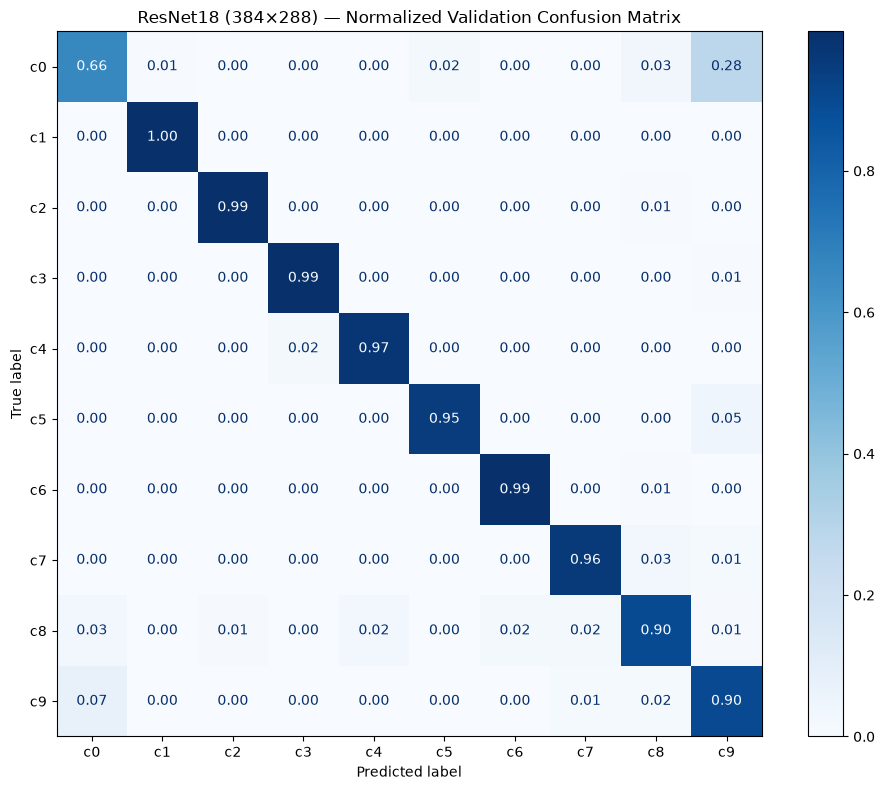


Inference completed!
Results saved: ../results/deep_learning/driver_based/resnet18/resolution_384x288/error_analysis


In [4]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. LOAD BEST TRAINED MODEL
# ============================================================

# Load the saved checkpoint from our 384x288 experiment
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

# Evaluation mode: no training
model.eval()

print("Loaded model:", best_model_path)
print("Input resolution:", f"{IMAGE_WIDTH}x{IMAGE_HEIGHT}")


# ============================================================
# 2. RUN INFERENCE ON ALL VALIDATION IMAGES
# ============================================================

y_true = []
y_pred = []
confidences = []

if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device)

        # Forward pass
        outputs = model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predicted class and confidence
        confidence, predictions = probabilities.max(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())
        confidences.extend(confidence.cpu().tolist())

if device.type == "cuda":
    torch.cuda.synchronize()

inference_time = time.perf_counter() - start_time


# ============================================================
# 3. CALCULATE PERFORMANCE
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=list(range(10)),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 50)
print("RESNET18 (384x288) — VALIDATION INFERENCE")
print("=" * 50)

print("Validation images:", len(y_true))

print(f"\nAccuracy: {accuracy:.4f} ({accuracy:.2%})")
print(f"Macro-F1: {macro_f1:.4f} ({macro_f1:.2%})")

print(f"\nInference time: {inference_time:.2f} seconds")


# ============================================================
# 4. PER-CLASS CLASSIFICATION REPORT
# ============================================================

class_names = [f"c{i}" for i in range(10)]

print("\nPER-CLASS CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)


# ============================================================
# 5. SAVE INDIVIDUAL PREDICTIONS
# ============================================================

prediction_df = val_df.reset_index(drop=True).copy()

# Verify predictions match the original validation order
assert len(prediction_df) == len(y_true)

assert prediction_df["classname"].str[1:].astype(int).tolist() == y_true

prediction_df["predicted"] = [f"c{x}" for x in y_pred]
prediction_df["confidence"] = confidences

prediction_df["correct"] = (
    prediction_df["classname"] == prediction_df["predicted"]
)


# ============================================================
# 6. DRIVER-SPECIFIC ACCURACY
# ============================================================

driver_results = (
    prediction_df
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nACCURACY BY DRIVER")
print("=" * 50)

print(driver_results.to_string())


# ============================================================
# 7. CREATE ANALYSIS DIRECTORY
# ============================================================

analysis_dir = exp_dir / "error_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

prediction_df.to_csv(
    analysis_dir / "validation_predictions.csv",
    index=False
)

driver_results.to_csv(
    analysis_dir / "driver_accuracy.csv"
)


# ============================================================
# 8. NORMALIZED CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(10)),
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title(
    "ResNet18 (384×288) — Normalized Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    analysis_dir / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. SAVE SUMMARY
# ============================================================

import json

inference_results = {
    "model": "ResNet18",
    "resolution": "384x288",
    "checkpoint": str(best_model_path),
    "validation_images": len(y_true),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "inference_time_seconds": float(inference_time)
}

with open(analysis_dir / "inference_results.json", "w") as f:
    json.dump(inference_results, f, indent=4)

print("\nInference completed!")
print("Results saved:", analysis_dir)

## 5. Safe Driving Misclassification Analysis

Investigate why ResNet18 frequently confuses safe driving (c0)
with talking to passengers (c9).

Analyze:
- Error frequency by driver
- Representative incorrectly classified images
- Prediction confidence
- Visual similarities between the activities

Total c0 → c9 mistakes: 104

Mistakes by driver:
subject
p047    55
p016    43
p075     6


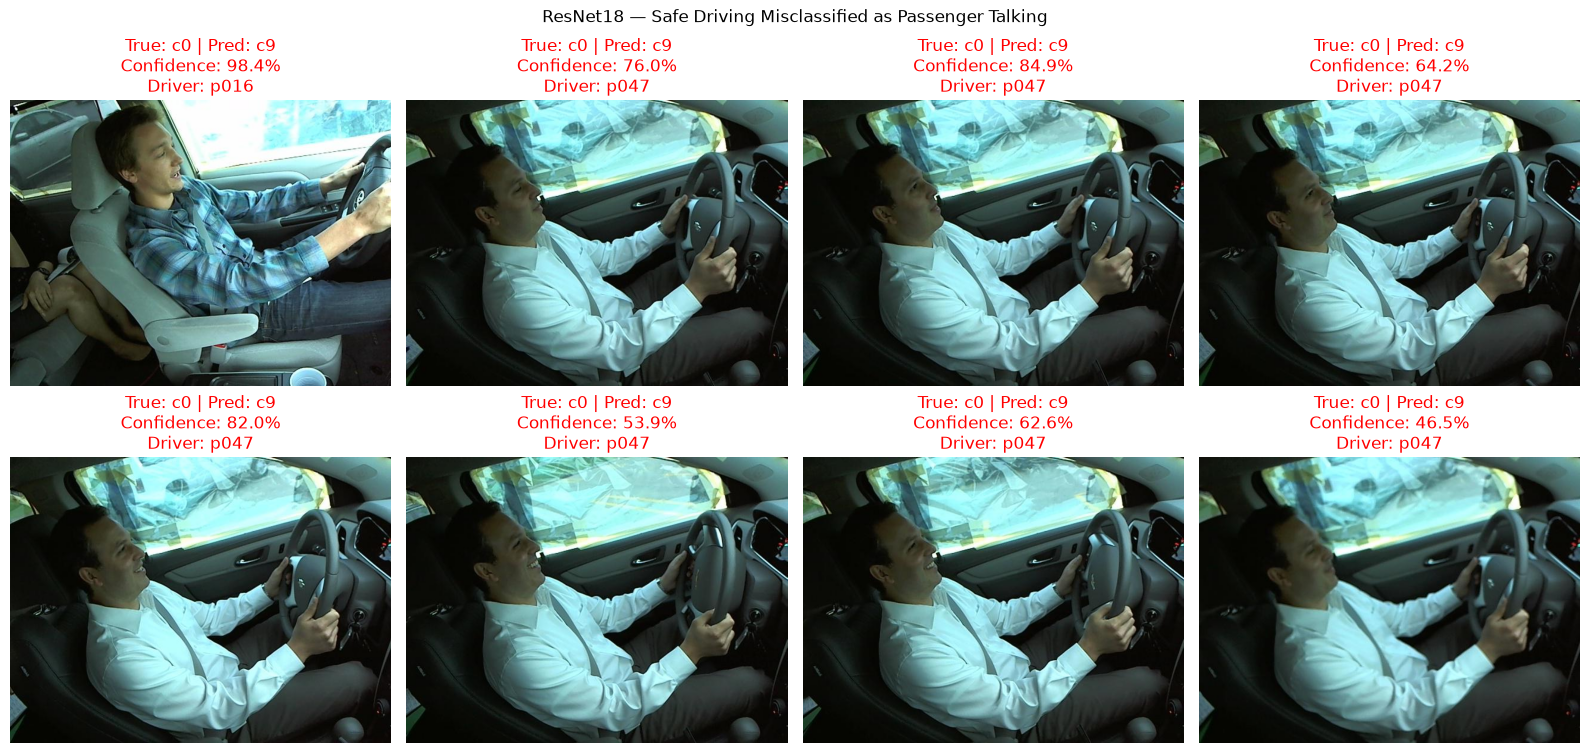

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

# Select safe-driving images incorrectly predicted as c9
c0_errors = prediction_df[
    (prediction_df["classname"] == "c0") &
    (prediction_df["predicted"] == "c9")
].copy()

print("Total c0 → c9 mistakes:", len(c0_errors))

# Check which drivers are responsible
print("\nMistakes by driver:")
print(
    c0_errors.groupby("subject")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

# Select 8 random examples
samples = c0_errors.sample(
    n=min(8, len(c0_errors)),
    random_state=42
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):

    image_path = (
        image_root /
        row["classname"] /
        row["img"]
    )

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f"True: c0 | Pred: c9\n"
        f"Confidence: {row['confidence']:.1%}\n"
        f"Driver: {row['subject']}",
        color="red"
    )

    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.suptitle("ResNet18 — Safe Driving Misclassified as Passenger Talking")

plt.tight_layout()

plt.savefig(
    analysis_dir / "c0_to_c9_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Visual Comparison — Safe Driving vs. Talking to Passenger

Compare images from c0 and c9 for the same validation driver.

Investigate whether the activities share similar visual patterns
and whether the model relies on ambiguous head or facial cues.

No retraining is performed.

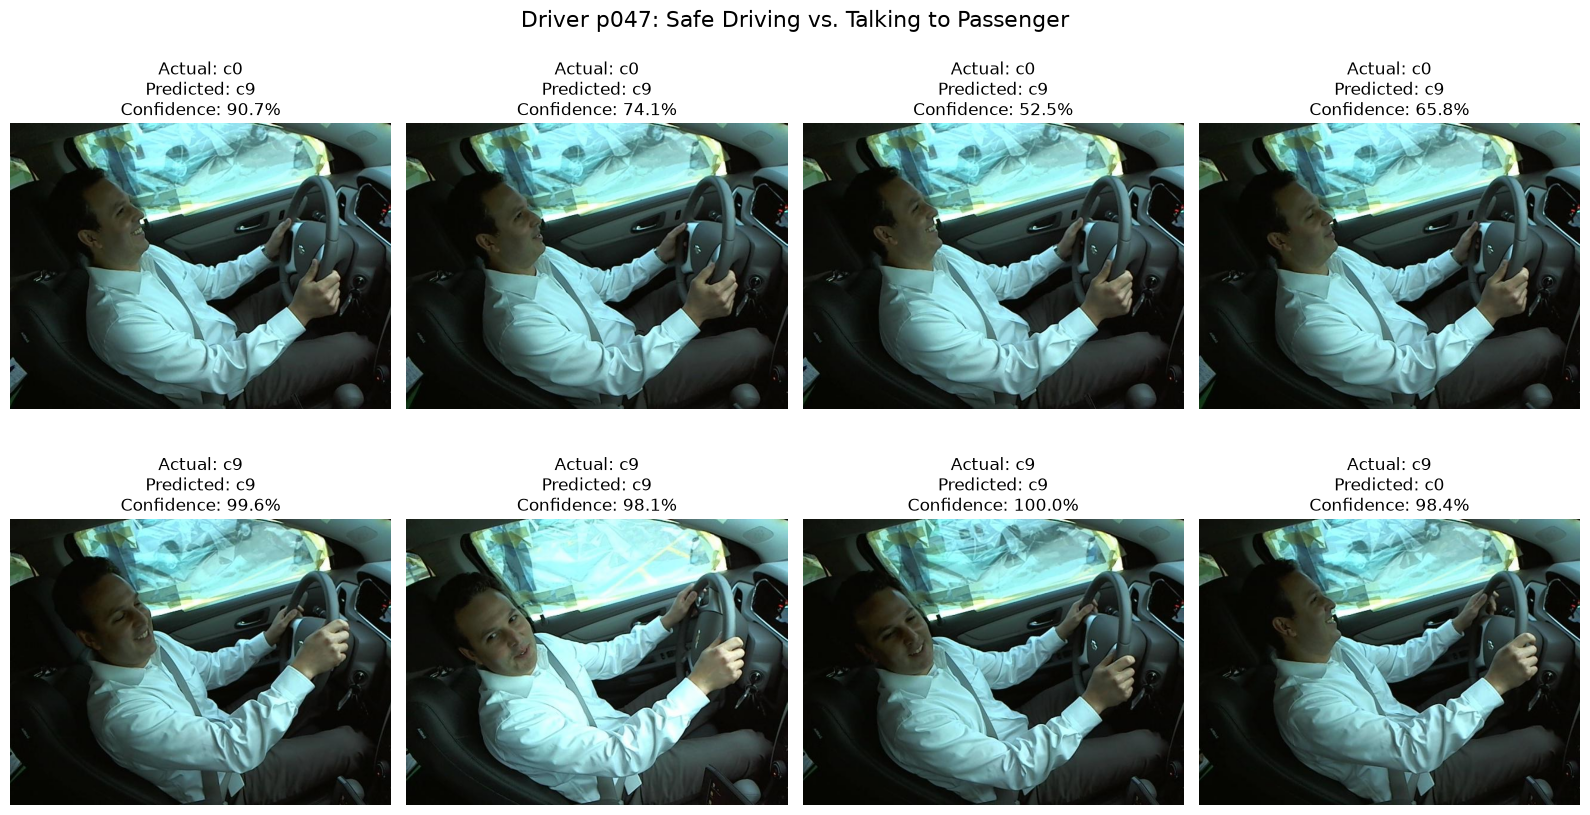

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

# Select driver with the most c0 → c9 mistakes
DRIVER = "p047"

# 1. Safe-driving images incorrectly classified as c9
c0_mistakes = prediction_df[
    (prediction_df["subject"] == DRIVER) &
    (prediction_df["classname"] == "c0") &
    (prediction_df["predicted"] == "c9")
].sample(n=4, random_state=42)

# 2. Actual talking-to-passenger images
c9_images = prediction_df[
    (prediction_df["subject"] == DRIVER) &
    (prediction_df["classname"] == "c9")
].sample(n=4, random_state=42)

# 3. Display images side by side
fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for row_idx, dataset in enumerate([c0_mistakes, c9_images]):

    for col_idx, (_, row) in enumerate(dataset.iterrows()):

        path = image_root / row["classname"] / row["img"]

        with Image.open(path) as img:
            axes[row_idx, col_idx].imshow(img.convert("RGB"))

        axes[row_idx, col_idx].set_title(
            f"Actual: {row['classname']}\n"
            f"Predicted: {row['predicted']}\n"
            f"Confidence: {row['confidence']:.1%}"
        )

        axes[row_idx, col_idx].axis("off")

plt.suptitle(
    f"Driver {DRIVER}: Safe Driving vs. Talking to Passenger",
    fontsize=16
)

plt.tight_layout()
plt.show()